__Tasks:__
- [x] Collect a MVD (Minimum Viable Data)
    - I'm using the 6-plex multiCas12a data from this [bioRxiv](https://www.biorxiv.org/content/10.1101/2023.09.18.558350v1.full.pdf)
- [x] Convert FASTQ to FASTA
    - Here, I start from processed FASTQ reads after I mearged R1/R2 using `pear` and then trimmed them to get expected molecules between two surrounding sequences.
    - Then, I'm using my custom codes to cound all unique sequences (i.e. reference free counting).
- [x] Prepare reference table.
- [ ] Map FASTA to FASTA!

___
See [my original notebook](https://github.com/GilbertLabUCSF/CHLG/blob/master/CHLG08/counts-2.ipynb) for processing the NGS data for 6-plex multiCas12a small screening experiment.

I made this repo ([PosSpacer](https://github.com/abearab/PosSpacer)) as a result but ... I ended up getting help from Noam to make a faster implementation called [casmap](https://github.com/noamteyssier/casmap/) which is based on his smart approch to resolve this problem.
___

# Collect data
A Minimum Viable Data (MVD)!

In [1]:
import subprocess

In [2]:
# subprocess.run(f'gsutil ls gs://crispr-screens/multiCas12a/CHLG08/',shell=True)

In [3]:
# !gsutil cp \
    # gs://crispr-screens/multiCas12a/CHLG08/Sample1_S1_L001_R1.fastq.gz \
    # ../multiCas12a_fastq/L001/Sample1_R1.fastq.gz
# !gsutil \
    # cp gs://crispr-screens/multiCas12a/CHLG08/Sample1_S1_L001_R2.fastq.gz \
    # ../multiCas12a_fastq/L001/Sample1_R2.fastq.gz

In [9]:
ls -lh multiCas12a_fastq/

total 3.4G
drwxr-xr-x 2 jupyter jupyter 4.0K Feb  6 07:42 L001/
-rw-r--r-- 1 jupyter jupyter 3.4G Feb  6 09:26 Sample1.assembled.trim.fastq.gz
drwxr-xr-x 3 jupyter jupyter 4.0K Feb  6 07:43 log/


In [6]:
# !gsutil \
#     cp gs://crispr-screens/multiCas12a/CHLG08/Sample1.assembled.trim.fastq.gz \
#     ../multiCas12a_fastq/Sample1.assembled.trim.fastq.gz

In [15]:
!seqkit stats -j 20 multiCas12a_fastq/Sample1.assembled.trim.fastq.gz -T

file	format	type	num_seqs	sum_len	min_len	avg_len	max_len
multiCas12a_fastq/Sample1.assembled.trim.fastq.gz	FASTQ	DNA	116223261	17893577444	16	154.0	464


# Count FASTQ ...
and save FASTA

In [9]:
import sys

sys.path.append('../../ScreenPro2/')

from screenpro import ngs

In [ ]:
%%time
Sample1 = ngs.fastq_to_count_unique_seq(
    "multiCas12a_fastq/Sample1.assembled.trim.fastq.gz"
)

load FASTQ file as a Polars DataFrame


In [ ]:
Sample1

In [11]:
%%time
Sample1 = ngs.fastq_to_count_unique_seq(
    "multiCas12a_fastq/Sample1.assembled.trim.fastq.gz",num_threads=1
)

load FASTQ file as a Polars DataFrame
done in 1628.641s
Count unique sequences
done in 9.085s
CPU times: user 27min 11s, sys: 50.7 s, total: 28min 1s
Wall time: 27min 26s


In [15]:
Sample1.write_ipc('multiCas12a_tables/Sample1.counts.allunique.arrow',compression = 'zstd')

In [32]:
import matplotlib.pyplot as plt

In [47]:
def cleanAxes(axis, top=False, right=False, bottom=True, left=True):
    axis.grid(None)
    axis.spines['top'].set_visible(top)
    axis.spines['right'].set_visible(right)
    axis.spines['left'].set_visible(left)
    axis.spines['bottom'].set_visible(bottom)

    #turn off all ticks
    axis.yaxis.set_ticks_position('none')
    axis.xaxis.set_ticks_position('none')

    #now re-enable visibles
    if top:
        axis.xaxis.tick_top()
    if bottom:
        axis.xaxis.tick_bottom()
    if left:
        axis.yaxis.tick_left()
    if right:
        axis.yaxis.tick_right()

def plot_seq_size_freq(data,title,yscale='linear'):
    fig, ax = plt.subplots(figsize=(4,2))
    data['seq'].str.lengths().to_pandas().hist(bins=100,ax=ax,alpha=.60)
    cleanAxes(ax)
    plt.suptitle(title)
    plt.yscale(yscale)
    plt.xlabel('sequence length')
    plt.ylabel('Freq.')
    plt.show()


def read_fasta(path):
    file = open(path)
    lines = file.read().splitlines()
    ids = [s[1:] for s in lines if '>' in s]
    n = [i for i,s in enumerate(lines) if '>' in s]
    n.append(len(lines))
    sequences = [''.join(lines[i+1:j]) for i,j in zip(n[:-1],n[1:])]
    file.close()
    fa = dict(zip(ids, sequences))
    return fa

def write_fasta(path, fa):
    file = open(path, 'w')
    for f in fa:
        file.write('>' + f + '\n')
        file.write(fa[f] + '\n')
    file.close()

In [41]:
Sample1_seq_length = Sample1['seq'].str.lengths().to_pandas()

/var/tmp/ipykernel_3191/3772925420.py:1: DeprecationWarning: `lengths` is deprecated. It has been renamed to `len_bytes`.
  Sample1_seq_length = Sample1['seq'].str.lengths().to_pandas()


/var/tmp/ipykernel_3191/565704781.py:24: DeprecationWarning: `lengths` is deprecated. It has been renamed to `len_bytes`.
  data['seq'].str.lengths().to_pandas().hist(bins=100,ax=ax,alpha=.60)


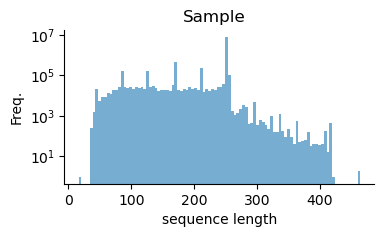

In [48]:
plot_seq_size_freq(Sample1,'Sample',yscale='log')

In [57]:
import polars as pl

In [69]:
Sample1_seqs = Sample1.filter(pl.col("count") >10).to_pandas()

In [85]:
Sample1_fa = dict([(f'>seq_{i+1} {Sample1_seqs['count'][i]}',Sample1_seqs['seq'][i]) for i in Sample1_seqs.index])

In [87]:
write_fasta('multiCas12a_tables/Sample1.counts.filt.fa',Sample1_fa)

# prepare reference sequences

In [117]:
DR_dict = {
    'pos1spacer': 'AATTTCTACTCTTGTAGAT',
    'pos2spacer': 'AATTTCTACTGTCGTAGAT',
    'pos3spacer': 'AATTCCTACTATTGTAGGT',
    'pos4spacer': 'AATTCCTACTCTAGTAGGT',
    'pos5spacer': 'AATTCCTACTCTCGTAGGT',
    'pos6spacer': 'AATTTCTACTCTAGTAGAT'
}

In [100]:
import pandas as pd

In [172]:
ref_table = pd.read_csv(
    'multiCas12a_tables/CHLG08_lib02spacersdf.txt.gz',sep='\t'
)

In [174]:
ref_table.columns

Index(['pos1spacer', 'pos2spacer', 'pos3spacer', 'pos4spacer', 'pos5spacer',
       'pos6spacer', 'pos1name', 'pos2name', 'pos3name', 'pos4name',
       'pos5name', 'pos6name', 'adapter', '5p', '3p', 'note', 'oligosequence',
       'oligoname', 'group'],
      dtype='object')

___
convert it to a list of spacer sequences and save as dictionary.

In [215]:
full_ref_spacers_fa = pd.concat([
    ref_table[[f'pos{n}spacer', f'pos{n}name']].rename(
        {f'pos{n}spacer':'sequence',f'pos{n}name':'name'},axis=1) for n in range(1,7)
]).drop_duplicates(keep='first').sort_values(
    'name',ascending=False
).reset_index(drop=True).set_index('name')['sequence'].to_dict()


full_ref_spacers_fa.update(DR_dict)

In [221]:
write_fasta(
    'multiCas12a_tables/reference.fa',
    full_ref_spacers_fa
)
!gzip 'multiCas12a_tables/reference.fa'

# map fasta2fasta

___

In [ ]:
'multiCas12a_tables/CHLG08_referencedf.fa'

In [93]:
# Sample1_fa

# 

In [231]:
%reload_ext watermark

%watermark
%watermark -iv

Last updated: 2024-02-07T08:01:58.122360+00:00

Python implementation: CPython
Python version       : 3.12.1
IPython version      : 8.20.0

Compiler    : GCC 12.3.0
OS          : Linux
Release     : 5.10.0-27-cloud-amd64
Machine     : x86_64
Processor   : 
CPU cores   : 16
Architecture: 64bit

pandas    : 2.1.4
polars    : 0.20.5
matplotlib: 3.8.2

